# Lista de Exercícios 4: Gradiente de Política

#### Disciplina: Aprendizado por Reforço
#### Professor: Luiz Chaimowicz
#### Monitor: Daniel Terra Gomes

---

## Instruções

- ***SUBMISSÕES QUE NÃO SEGUIREM AS INSTRUÇÕES A SEGUIR NÃO SERÃO AVALIADAS.***
- Leia atentamente toda a lista de exercícios e familiarize-se com o código fornecido antes de começar a implementação.
- Os locais onde você deverá escrever suas soluções estão demarcados com comentários `# YOUR CODE HERE` ou `YOUR ANSWER HERE`.
- **Não altere o código fora das áreas indicadas, nem adicione ou remova células. O nome deste arquivo também não deve ser modificado.**
- Antes de submeter, certifique-se de que o código esteja funcionando do início ao fim sem erros.
- Submeta apenas este notebook (*ps4.ipynb*) com as suas soluções no Moodle.
- Prazo de entrega: 20/11/2026. Submissões fora do prazo terão uma penalização de -20% da nota final por dia de atraso.
- Utilize a [documentação do Gymnasium](https://gymnasium.farama.org/) para auxiliar sua implementação.
- Em caso de dúvidas entre em contato pelo fórum "Dúvidas com relação aos exercícios e trabalho de curso" no moodle da Disciplina.

---

## Cart Pole

Cart Pole é um ambiente no qual o agente precisa equilibrar um pêndulo invertido acoplado a um carrinho que se move horizontalmente. O objetivo é evitar que o pêndulo caia, controlando a posição do carrinho de maneira apropriada. O desafio está em manter o equilíbrio do sistema aplicando forças para a esquerda ou para a direita, de modo a contrabalançar a inclinação do pêndulo.

![Cart Pole](https://gymnasium.farama.org/_images/cart_pole.gif)

O espaço de observação é contínuo e composto por quatro variáveis: a posição e a velocidade do carrinho, o ângulo do pêndulo e a velocidade angular do pêndulo. O agente pode escolher entre duas ações discretas: aplicar uma força no carrinho para a esquerda ou para a direita. O estado inicial de cada episódio é definido de forma aleatória, com todos os valores dentro do intervalo $(−0.05, 0.05)$. O sempre sistema começa em uma configuração próxima do equilíbrio vertical, mas com pequenas variações.

O episódio termina quando o ângulo do pêndulo em relação ao eixo vertical excede 12 graus, quando o carrinho se afasta mais de 2.4 unidades de distância do centro, ou quando o limite de 500 passos é atingido. A cada passo, o agente recebe uma recompensa de $1$, incentivando-o a manter o sistema estável pelo maior tempo possível. Para mais detalhes sobre o ambiente leia a [documentação do gymnasium](https://gymnasium.farama.org/environments/classic_control/cart_pole/).

Nesta lista de exercícios, você irá trabalhar com o ambiente Cart Pole descrito acima. Seu objetivo será implementar o algoritmo REINFORCE para solucionar este problema.

## REINFORCE

Nesta atividade, você implementará um agente baseado no algoritmo REINFORCE, utilizando uma **política linear com softmax**. Você será responsável por definir e inicializar os pesos da política, calcular o gradiente da função objetivo e realizar a atualização dos parâmetros ao longo do treinamento.

Siga as instruções abaixo para implementar seu agente:

1. Implemente o método `__init__` que inicializa um novo agente. Ele deve receber como parâmetros o espaço de observações, o espaço de ações, a taxa de aprendizado $\alpha$, e o fator de desconto $\gamma$. Inicialize os pesos do modelo na variável `self.weights`.
2. Implemente o método `softmax`, que recebe um vetor de preferências (logits) $z = (z_1,\dotsc,z_K) \in \mathbb{R}^K$ e retorna as probabilidades de cada ação segundo a função softmax $\sigma(z)_i = \frac{e^{z_i}}{\sum_{j=1}^{K} e^{z_j}}$, para $i = 1, \dotsc, K.$
3. Implemente o método `choose_action`, responsável por escolher uma ação a partir de um estado observado.
4. Implemente o método `learn`, que atualiza os pesos do agente com base na experiência obtida durante a interação com o ambiente.
5. Implemente o método `train`, que executa o loop de treinamento do algoritmo REINFORCE. O ambiente de treinamento e o número de episódios devem ser fornecidos como parâmetros de entrada. O método deve retornar uma lista com a soma das recompensas obtidas ao longo de cada episódio.

In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

In [23]:
class ReinforceAgent:
    def __init__(self, observation_space, action_space, alpha, gamma):
        self.observation_space = observation_space
        self.action_space = action_space
        self.alpha = alpha
        self.gamma = gamma

        self.obs_dim = observation_space.shape[0]
        self.acs_dim = action_space.n

        self.weights = np.zeros((self.obs_dim,self.acs_dim))

    def softmax(self, z):
        numerator = np.exp(z)
        den = numerator.sum()

        return numerator/den

    def choose_action(self, state):
        probs = self.softmax(state @ self.weights)

        return np.random.choice(self.acs_dim, p=probs)

    def learn(self, trajectories):
        G = 0
        discounted_returns = []
        for _, _, reward in reversed(trajectories):
            G = reward + self.gamma * G
            discounted_returns.append(G)
        discounted_returns.reverse()

        grad_sum = np.zeros((self.obs_dim, self.acs_dim))
        for t, (state, action, _) in enumerate(trajectories):
            probs = self.softmax(state @ self.weights)
            one_hot = np.zeros(self.acs_dim)
            one_hot[action] = 1.0
            grad = np.outer(state, one_hot - probs)
            grad_sum += (self.gamma ** t) * discounted_returns[t] * grad
        self.weights += self.alpha * grad_sum


    def train(self, env, episodes):
        episodic_rewards = []

        for _ in range(episodes):
            state, _ = env.reset()
            trajectories = []
            total_reward = 0
            done = False

            while not done:
                action = self.choose_action(state)
                next_state, reward, terminated, truncated, _ = env.step(action)
                trajectories.append((state, action, reward))
                total_reward += reward
                state = next_state
                done = terminated or truncated

            self.learn(trajectories)
            episodic_rewards.append(total_reward)

        return episodic_rewards

In [ ]:
# Não altere ou remova esta célula

6. Treine um novo agente no ambiente Cart Pole por 2000 episódios. Escolha parâmetros $\alpha$ e $\gamma$ de acordo com o desempenho do seu modelo. Armazene os retornos episódicos, obtidos no método `train`, na variável `reinforce_returns`.

In [39]:
env = gym.make("CartPole-v1")

# de 0.1 em 0.1
alpha = 0.01
gamma = 0.99

episodes_amount = 2000

observation, info = env.reset(seed=2026)
agent = ReinforceAgent(
    env.observation_space,
    env.action_space,
    alpha,
    gamma
)

reinforce_returns = agent.train(env, episodes_amount)

env.close()

In [ ]:
# Não altere ou remova esta célula

## Análise

7. Utilize a biblioteca matplotlib para gerar um gráfico dos retornos episódicos obtidos pelo agente, armazenados na variável `reinforce_returns` no exercício anterior. Caso os dados apresentem muita variação, aplique uma média móvel para suavizar a curva e evidenciar melhor a tendência de aprendizado. Adicione um título e rótulos de eixos apropriados para facilitar a interpretação.

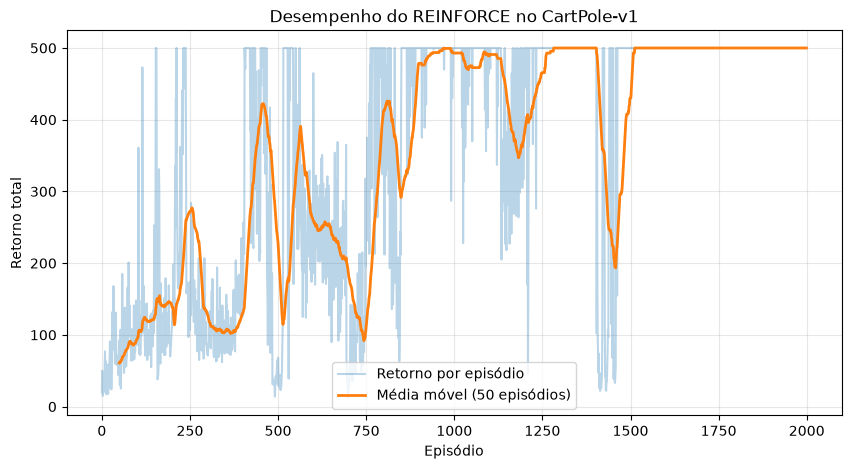

In [41]:
# YOUR CODE HERE
window = 50
moving_avg = np.convolve(reinforce_returns, np.ones(window) / window, mode="valid")
plt.figure(figsize=(10, 5))
plt.plot(reinforce_returns, alpha=0.3, label="Retorno por episódio")
plt.plot(
    range(window - 1, len(reinforce_returns)),
    moving_avg,
    linewidth=2,
    label=f"Média móvel ({window} episódios)",
)
plt.title("Desempenho do REINFORCE no CartPole-v1")
plt.xlabel("Episódio")
plt.ylabel("Retorno total")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

8. Durante o treinamento, o seu agente apresentou instabilidades, como variações bruscas na recompensa ou dificuldade em convergir? Que estratégias poderiam ser adotadas para mitigar instabilidades neste algoritmo?

Sim, o agente apresentou muitas instabilidades durante o treinamento, observei alta variância nos retornos ao longo de quase todos os episódios, quedas repentinas no desempenho mesmo depois de melhorar por um tempo, e grande variação entre diferentes runs. 
Além disso, o algoritmo mostrou-se muito sensível a (1) alpha, pois valores altos tornaram o treinamento instável ou impediram completamente a convergência, enquanto reduzir o $\alpha$ melhorou a estabilidade. O $\gamma = 0$ impediu qualquer aprendizado (pois o retorno imediato no CartPole é sempre $1$, e não estavamos olhando a prazo maior que isso), valores altos de $\gamma$ tornaram o processo mais estável, e $\gamma = 0.99$ superou $\gamma = 1$ por limitar a magnitude dos retornos $G_t$ e reduzir a variância associada a recompensas muito distantes.

Para mitigar essas instabilidades, podem ser adotadas as seguintes estratégias

(1) Subtrair um baseline $b(S_t)$ (o REINFORCE com baseline)

(2) Normalizar os retornos G_t

(3) Decaimento da taxa de aprendizado $\alpha$

(4) Poderiamos fazer Gradient clipping

(5) Regularização por entropia

9. Explique qual é o papel da função softmax na definição da política. Por que, nesse contexto, não é suficiente escolher apenas a ação com maior valor?

A função softmax converte o vetor de preferências (os logits) $z = sW$ em uma distribuição de probabilidades válida $\pi_\theta(a \mid s)$ sobre o espaço discreto de ações, garantindo que todas as probabilidades estejam no intervalo $(0, 1)$ e somem $1$. Dessa forma, ela define uma política estocástica e diferenciável em função dos parâmetros $\theta$.

Escolher apenas a ação de maior valor ($\arg\max$) não é suficiente nesse contexto por dois motivos principais:
(1) O operador $\arg\max$ não é diferenciável, o que impede o cálculo de $\nabla_\theta \ln \pi_\theta(a \mid s)$ necessário para atualizar os pesos no REINFORCE. A softmax, por ser suave e diferenciável, permite que pequenas mudanças nos pesos produzam mudanças contínuas nas probabilidades das ações.
(2) Uma escolha puramente gulosa ($\arg\max$) torna a política determinística, impedindo o agente de experimentar ações alternativas e fazendo com que ele fique facilmente preso em políticas subótimas (especialmente no início do treinamento, quando os pesos ainda não refletem boas ações). A softmax mantém probabilidade não nula para todas as ações, garantindo exploração natural enquanto ainda favorece ações com maiores preferências.

10. Por que o algoritmo REINFORCE precisa aguardar a conclusão de todo o episódio antes de realizar atualizações nos parâmetros da política?

O algoritmo REINFORCE precisa aguardar o término completo do episódio porque é um método de Monte Carlo que utiliza o retorno total descontado para atualizar os parâmetros da política ($G_t = \sum_{k=t}^{T-1} \gamma^{k-t} R_{k+1}$).

Como o cálculo de $G_t$ para qualquer passo $t$ depende de todas as recompensas futuras até o passo final $T$, esse valor simplesmente não é conhecido antes de o episódio encerrar.

Além disso, isso garante que estamos on-policy, pois aguardar o fim do episódio também garante que toda a trajetória tenha sido gerada por uma mesma política $\pi_\theta$ antes de modificá-la.